# Experimental compression of the 7.5° sectors

Analysis of the physical tests of **Sections 4.7 and 5.13** of the thesis ([`docs/TO_Final_Inform_FLP.pdf`](../docs/TO_Final_Inform_FLP.pdf)) and comparison with the predictions of the virtual test of `Final.ipynb` (Blocks 7 and 8).

Full-scale 7.5° sectors were compressed axially between flat platens in an Instron 3369 universal testing machine, at a constant crosshead speed of 2 mm/min and 24 h after printing. There are **nine records, one per design**: five PA6 designs and four single-case PA6-CF designs. The multi-load PA6-CF sector could not be printed because of moisture-related printing problems.

**Inputs:** `data/sector_tests/PA6TO_*.csv`, `PA6CFTO_*.csv`. **Outputs:** `results/sector_tests/`.

These statistics describe different designs. With one record per design, they do not estimate the repeatability between specimens.

In [1]:
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "sector_tests"
OUT = ROOT / "results" / "sector_tests"
OUT.mkdir(parents=True, exist_ok=True)

# Test matrix: material, file, design
TESTS = [("PA6", "PA6TO_1.csv", "Multi"), ("PA6", "PA6TO_2.csv", "C4"), ("PA6", "PA6TO_3.csv", "C3"), ("PA6", "PA6TO_4.csv", "C2"), ("PA6", "PA6TO_5.csv", "C1"),
         ("PA6-CF", "PA6CFTO_1.csv", "C1"), ("PA6-CF", "PA6CFTO_2.csv", "C2"), ("PA6-CF", "PA6CFTO_3.csv", "C3"), ("PA6-CF", "PA6CFTO_4.csv", "C4")]

H_MM = 81.0                  # Height of the sector, equal to that of the component [mm]

# Analysis settings (Sec. 5.13)
BAND_MAIN = (0.20, 0.50)     # Force band of the stiffness fit, as a fraction of the measured maximum
BANDS_ALT = [(0.10, 0.40), (0.30, 0.60)]   # Alternative bands, to measure the sensitivity to the choice of band
DROP_REL = 0.03              # A load drop exceeds this fraction of F_max ...
DROP_DX = 0.05               # ... within this displacement window [mm]
STEEP_WINDOW = 15            # Points of the steepest-slope window, only for comparison
WARN_R2 = 0.995              # Warns if the fit has a lower R2
WARN_K_RATIO = 0.70          # Warns if the fitted slope is below this fraction of the steepest local slope

DESIGN_ORDER = ["Multi", "C1", "C2", "C3", "C4"]
COLORS = {"Multi": "#1f77b4", "C1": "#d62728", "C2": "#2ca02c", "C3": "#ff7f0e", "C4": "#9467bd"}
MAT_COLORS = {"PA6": "#2563eb", "PA6-CF": "#ea580c"}

## 1. Predictions for the sectors (Table 5.12.1)

The ring results of Block 8 are converted with the angular factor of Eq. (4.3), and the masses come from the sector STL files:

$$K_{pred} = \frac{\theta}{360}K_{ini},\qquad F_{pred} = \frac{\theta}{360}F_{col},\qquad \frac{\theta}{360} = \frac{1}{48}.$$

$K_{pred}$ is an elastic upper bound conditional on equivalent geometry, material properties and prescribed loading, and $F_{pred}$ is indicative. The values below are those of the thesis.

In [2]:
# K_pred [N/mm], F_pred [N], force at the yield onset Fy_pred [N] and sector mass [g]
PRED = {("PA6", "Multi"): dict(K=562.16, F=6505.6, Fy=4731.3, m=20.06), ("PA6", "C1"): dict(K=301.04, F=3519.2, Fy=2468.8, m=13.19),
        ("PA6", "C2"): dict(K=223.21, F=2576.5, Fy=1681.3, m=11.06), ("PA6", "C3"): dict(K=345.79, F=3938.1, Fy=2720.8, m=14.21),
        ("PA6", "C4"): dict(K=193.32, F=1782.8, Fy=1247.9, m=14.37), ("PA6-CF", "Multi"): dict(K=632.14, F=1612.1, Fy=1183.3, m=11.15),
        ("PA6-CF", "C1"): dict(K=469.59, F=1227.8, Fy=868.8, m=9.42), ("PA6-CF", "C2"): dict(K=416.01, F=986.7, Fy=595.8, m=9.64),
        ("PA6-CF", "C3"): dict(K=466.31, F=1181.0, Fy=768.8, m=9.09), ("PA6-CF", "C4"): dict(K=293.31, F=719.1, Fy=489.6, m=10.02)}

# Consistency with the virtual test of Final.ipynb, if its results are available
vtest_file = ROOT / "results" / "virtual_test" / "virtual_test_table.csv"
if vtest_file.exists():
    vt = pd.read_csv(vtest_file)
    vt["mat"] = vt.material.replace({"PA6_CF": "PA6-CF"})
    vt["des"] = vt.design.replace({"Multi-load": "Multi"})
    errors = [abs(r.K_pred_kN_mm * 1e3 - PRED[(r.mat, r.des)]["K"]) / PRED[(r.mat, r.des)]["K"] for r in vt.itertuples() if (r.mat, r.des) in PRED]
    print(f"Largest difference between K_pred here and in results/virtual_test/: {100 * max(errors):.3f} %")

Largest difference between K_pred here and in results/virtual_test/: 0.002 %


## 2. Reading the machine records

Each CSV has an empty first row, a header and a row of units, with `;` as separator and `,` as decimal mark.

In [3]:
def load_test(path):
    # Force [N] and platen displacement [mm] of one record.
    df = pd.read_csv(path, sep=";", decimal=",", quotechar='"', skiprows=[0, 2], skip_blank_lines=False, encoding="latin1").iloc[:, :2]
    df.columns = ["F_N", "x_mm"]
    return df.dropna().astype(float).reset_index(drop=True)

## 3. Data reduction (Sec. 4.7.2, 5.13)

- **Stiffness:** the processing fits $F = K_{exp}\delta + b$ between 20 % and 50 % of the measured maximum force, using points before the peak or the first detected load drop. No band overrides or machine-compliance correction are applied.
- **Displacement origin:** shifted by $\delta_0 = -b/K_{exp}$. This translation leaves the fitted stiffness unchanged and does not remove nonlinear seating from a fit that includes it.
- **Load drops:** detected over a displacement window and with a threshold relative to $F_{max}$, so the detection does not depend on the sampling rate.
- **Sensitivity:** two alternative bands, 10-40 % and 30-60 %, measure how much the stiffness depends on the band. The steepest local slope is computed only as a comparison, since it is an upper estimate.

In [4]:
def linear_fit(x, y):
    # Least-squares line: slope, intercept and R2.
    p = np.polyfit(x, y, 1)
    ss_res = float(np.sum((y - np.polyval(p, x)) ** 2))
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    return float(p[0]), float(p[1]), 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan


def detect_drops(x, y, f_ref):
    # Load drops larger than DROP_REL*f_ref within a displacement DROP_DX.
    events, i, n = [], 0, len(x)
    while i < n - 1:
        j = i + 1
        while j < n and x[j] - x[i] <= DROP_DX:
            j += 1
        seg = y[i:j]
        k_min = int(np.argmin(seg))
        if y[i] - seg[k_min] > DROP_REL * f_ref:
            i_end = i + k_min
            events.append(dict(i_start=i, i_end=i_end, x=float(x[i]), F_before=float(y[i]), F_after=float(y[i_end]), dF=float(y[i_end] - y[i])))
            i = i_end + 1
        else:
            i += 1
    return events


def band_fit(x, y, f_max, i_limit, band):
    # Fit on the ascending branch (indices below i_limit) for forces inside the band.
    lo, hi = band[0] * f_max, band[1] * f_max
    idx = np.arange(i_limit)
    sel = idx[(y[:i_limit] >= lo) & (y[:i_limit] <= hi)]
    if len(sel) < 5:
        return dict(k=np.nan, b=np.nan, r2=np.nan, n=len(sel))
    k, b, r2 = linear_fit(x[sel], y[sel])
    return dict(k=k, b=b, r2=r2, n=int(len(sel)))


def steepest_slope(x, y, i_limit, r2_min=0.99):
    # Largest local slope with R2 above r2_min before i_limit, only for comparison.
    best = np.nan
    for i in range(0, max(0, i_limit - STEEP_WINDOW)):
        xw, yw = x[i:i + STEEP_WINDOW], y[i:i + STEEP_WINDOW]
        if xw[-1] - xw[0] <= 0.05:
            continue
        k, _, r2 = linear_fit(xw, yw)
        if r2 > r2_min and (np.isnan(best) or k > best):
            best = k
    return best


def analyze(df):
    # Stiffness, corrected displacement, peak and load drops of one test.
    y, x = df["F_N"].to_numpy(), df["x_mm"].to_numpy()
    i_peak = int(np.argmax(y))
    f_max = float(y[i_peak])
    drops = detect_drops(x, y, f_max)
    before_peak = [d for d in drops if d["i_start"] < i_peak]
    i_limit = max(before_peak[0]["i_start"] if before_peak else i_peak, 6)   # The ascending branch ends at the first drop or at the peak

    main = band_fit(x, y, f_max, i_limit, BAND_MAIN)
    alts = [band_fit(x, y, f_max, i_limit, b) for b in BANDS_ALT]
    ks = [main["k"]] + [a["k"] for a in alts]
    x0 = -main["b"] / main["k"]
    xc = x - x0
    first = drops[0] if drops else None
    return dict(x=x, xc=xc, y=y, i_peak=i_peak, drops=drops, F_max=f_max, x_peak=float(xc[i_peak]), strain_peak_pct=100.0 * float(xc[i_peak]) / H_MM, x0=float(x0),
                k=main["k"], k_b=main["b"], k_r2=main["r2"], k_n=main["n"], k_alt1=alts[0]["k"], k_alt2=alts[1]["k"], k_spread=(np.nanmax(ks) - np.nanmin(ks)) / main["k"],
                k_steep=steepest_slope(x, y, i_limit), first_drop_x=float(first["x"] - x0) if first else np.nan, first_drop_F=float(first["F_before"]) if first else np.nan,
                first_drop_before_peak=bool(before_peak), n_drops=len(drops), F_end=float(y[-1]), x_end=float(xc[-1]),
                E_peak_J=float(trapezoid(np.clip(y[:i_peak + 1], 0, None), np.clip(xc[:i_peak + 1], 0, None)) / 1000.0))


def spearman_exact(a, b):
    # Spearman coefficient and exact two-sided permutation p-value (small n, no ties).
    a, b = np.asarray(a, float), np.asarray(b, float)
    ra, rb = a.argsort().argsort(), b.argsort().argsort()
    n = len(a)
    d2 = lambda r: float(np.sum((ra - np.asarray(r)) ** 2))
    rho = 1 - 6 * d2(rb) / (n * (n * n - 1))
    perms = [1 - 6 * d2(p) / (n * (n * n - 1)) for p in permutations(range(n))]
    return rho, float(np.mean([abs(r) >= abs(rho) - 1e-12 for r in perms]))

In [5]:
rows, curves = [], {}
for mat, fname, design in TESTS:
    r = analyze(load_test(DATA / fname))
    curves[(mat, design)] = r
    p = PRED[(mat, design)]
    if r["k_r2"] < WARN_R2:
        print(f"WARNING {mat} {design}: R2 of the fit = {r['k_r2']:.4f}, below {WARN_R2}")
    if r["k"] < WARN_K_RATIO * r["k_steep"]:
        print(f"WARNING {mat} {design}: fitted slope {r['k']:.0f} N/mm is below {100 * WARN_K_RATIO:.0f} % of the steepest local slope ({r['k_steep']:.0f} N/mm)")
    rows.append(dict(material=mat, design=design, file=fname, K_exp_N_mm=r["k"], R2=r["k_r2"], n_points=r["k_n"], K_10_40=r["k_alt1"], K_30_60=r["k_alt2"], band_spread=r["k_spread"],
                     K_steepest=r["k_steep"], K_pred_N_mm=p["K"], K_ratio=r["k"] / p["K"], delta_0_mm=r["x0"], F_max_N=r["F_max"], delta_max_mm=r["x_peak"], delta_max_over_H_pct=r["strain_peak_pct"],
                     F_pred_N=p["F"], F_ratio=r["F_max"] / p["F"], Fy_pred_N=p["Fy"], m_sector_g=p["m"], K_per_g=r["k"] / p["m"], first_drop_mm=r["first_drop_x"], first_drop_N=r["first_drop_F"],
                     first_drop_before_peak=r["first_drop_before_peak"], n_drops=r["n_drops"], E_peak_J=r["E_peak_J"], F_end_N=r["F_end"], delta_end_mm=r["x_end"]))
S = pd.DataFrame(rows)
S.to_csv(OUT / "T_EXP_01_summary.csv", index=False, encoding="utf-8-sig")

WARNING PA6-CF C1: fitted slope 160 N/mm is below 70 % of the steepest local slope (315 N/mm)
WARNING PA6-CF C4: R2 of the fit = 0.9673, below 0.995
WARNING PA6-CF C4: fitted slope 113 N/mm is below 70 % of the steepest local slope (186 N/mm)


## 4. Results (Table 5.13.1)

Stiffness and force are given in kN/mm and kN. Displacements are shifted by the fitted intercept.

In [6]:
order = {d: i for i, d in enumerate(DESIGN_ORDER)}
table_5_13_1 = pd.DataFrame(dict(material=S.material, design=S.design.replace({"Multi": "Multi-load"}), K_exp=S.K_exp_N_mm / 1e3, K_pred=S.K_pred_N_mm / 1e3, K_exp_over_K_pred=S.K_ratio,
                                 F_max_exp=S.F_max_N / 1e3, F_max_over_F_pred=S.F_ratio, delta_max_mm=S.delta_max_mm, delta_max_over_H_pct=S.delta_max_over_H_pct, _o=S.design.map(order)))
table_5_13_1 = table_5_13_1.sort_values(["material", "_o"]).drop(columns="_o").reset_index(drop=True)
table_5_13_1.to_csv(OUT / "table_5_13_1.csv", index=False)
table_5_13_1.round(3)

,material,design,K_exp,K_pred,K_exp_over_K_pred,F_max_exp,F_max_over_F_pred,delta_max_mm,delta_max_over_H_pct
0,PA6,Multi-load,2.126,0.562,3.782,4.436,0.682,2.313,2.856
1,PA6,C1,0.957,0.301,3.179,0.569,0.162,1.315,1.624
2,PA6,C2,0.702,0.223,3.146,0.950,0.369,1.537,1.898
3,PA6,C3,1.452,0.346,4.199,2.156,0.547,2.102,2.595
4,PA6,C4,0.658,0.193,3.405,0.717,0.402,1.138,1.405
5,PA6-CF,C1,0.160,0.470,0.341,0.160,0.131,0.935,1.154
6,PA6-CF,C2,0.417,0.416,1.002,0.525,0.532,1.782,2.199
7,PA6-CF,C3,0.397,0.466,0.852,0.522,0.442,2.218,2.738
8,PA6-CF,C4,0.113,0.293,0.384,0.225,0.312,2.354,2.906


## 5. Stiffness and relative design response (Sec. 5.13.1)

Ratios of measured to predicted stiffness per material, and rank correlation between the measured and predicted orders. In PA6, the experimental order is exactly the predicted one, with a mean ratio close to 3.5. In PA6-CF, the predicted ranking is not preserved. For C1 and C4, the slope depends strongly on the fit interval, so they are fit-dependent apparent stiffnesses rather than well-isolated initial elastic stiffnesses.

In [7]:
stats = []
for mat in ["PA6", "PA6-CF"]:
    s = S[S.material == mat]
    q = s.K_ratio.to_numpy()
    rho, pval = spearman_exact(s.K_exp_N_mm, s.K_pred_N_mm)
    stats.append(dict(material=mat, n=len(s), ratio_mean=q.mean(), ratio_sd=q.std(ddof=1), ratio_cv_pct=100 * q.std(ddof=1) / q.mean(), ratio_min=q.min(), ratio_max=q.max(), spearman_rho=rho, spearman_p_exact=pval))
ST = pd.DataFrame(stats)
ST.to_csv(OUT / "T_EXP_02_ratio_statistics.csv", index=False, encoding="utf-8-sig")
print(ST.round(3).to_string(index=False))

print("\nSensitivity of the stiffness to the fit band, normalized by the main fit:")
print(S[["material", "design", "K_exp_N_mm", "K_10_40", "K_30_60", "band_spread", "K_steepest", "R2"]].round(3).to_string(index=False))

material  n  ratio_mean  ratio_sd  ratio_cv_pct  ratio_min  ratio_max  spearman_rho  spearman_p_exact
     PA6  5       3.542     0.446        12.592      3.146      4.199           1.0             0.017
  PA6-CF  4       0.645     0.332        51.508      0.341      1.002           0.2             0.917

Sensitivity of the stiffness to the fit band, normalized by the main fit:
material design  K_exp_N_mm  K_10_40  K_30_60  band_spread  K_steepest    R2
     PA6  Multi    2126.104 2061.421 2147.742        0.041    2170.266 1.000
     PA6     C4     658.203  458.756  666.785        0.316     671.931 1.000
     PA6     C3    1451.930 1452.133 1265.697        0.128    1477.341 1.000
     PA6     C2     702.317  609.223  725.420        0.165     730.001 0.999
     PA6     C1     957.152  898.494  954.423        0.061     953.124 1.000
  PA6-CF     C1     160.088  145.953  204.094        0.363     314.604 0.996
  PA6-CF     C2     416.854  346.761  414.272        0.168     424.511 1.000
  P

## 6. PA6-CF against PA6 (Sec. 5.13.2)

For C1 to C4, the model predicts PA6-CF-to-PA6 stiffness ratios of 1.35 to 1.86, while the measurements give 0.17 to 0.59. Each material has its own optimized topology, so this reversal combines material, geometry and manufacturing effects. It does not measure the effect of the carbon-fiber reinforcement at fixed geometry.

In [8]:
cmp_rows = []
for d in DESIGN_ORDER:
    a, b = S[(S.material == "PA6") & (S.design == d)], S[(S.material == "PA6-CF") & (S.design == d)]
    if len(a) and len(b):
        a, b = a.iloc[0], b.iloc[0]
        cmp_rows.append(dict(design=d, K_CF_over_PA6_measured=b.K_exp_N_mm / a.K_exp_N_mm, K_CF_over_PA6_predicted=b.K_pred_N_mm / a.K_pred_N_mm, Fmax_CF_over_PA6_measured=b.F_max_N / a.F_max_N))
CMP = pd.DataFrame(cmp_rows)
CMP.to_csv(OUT / "T_EXP_03_CF_over_PA6.csv", index=False, encoding="utf-8-sig")
CMP.round(3)

,design,K_CF_over_PA6_measured,K_CF_over_PA6_predicted,Fmax_CF_over_PA6_measured
0,C1,0.167,1.560,0.282
1,C2,0.594,1.864,0.553
2,C3,0.274,1.349,0.242
3,C4,0.171,1.517,0.313


## 7. Figures

`F_EXP_01` is **Figure 5.13.1** and `F_EXP_03` is **Figure 5.13.2** of the thesis. The others show the individual fits, the ratios to the predictions, the pattern between designs and the sensitivity of the stiffness to the method.

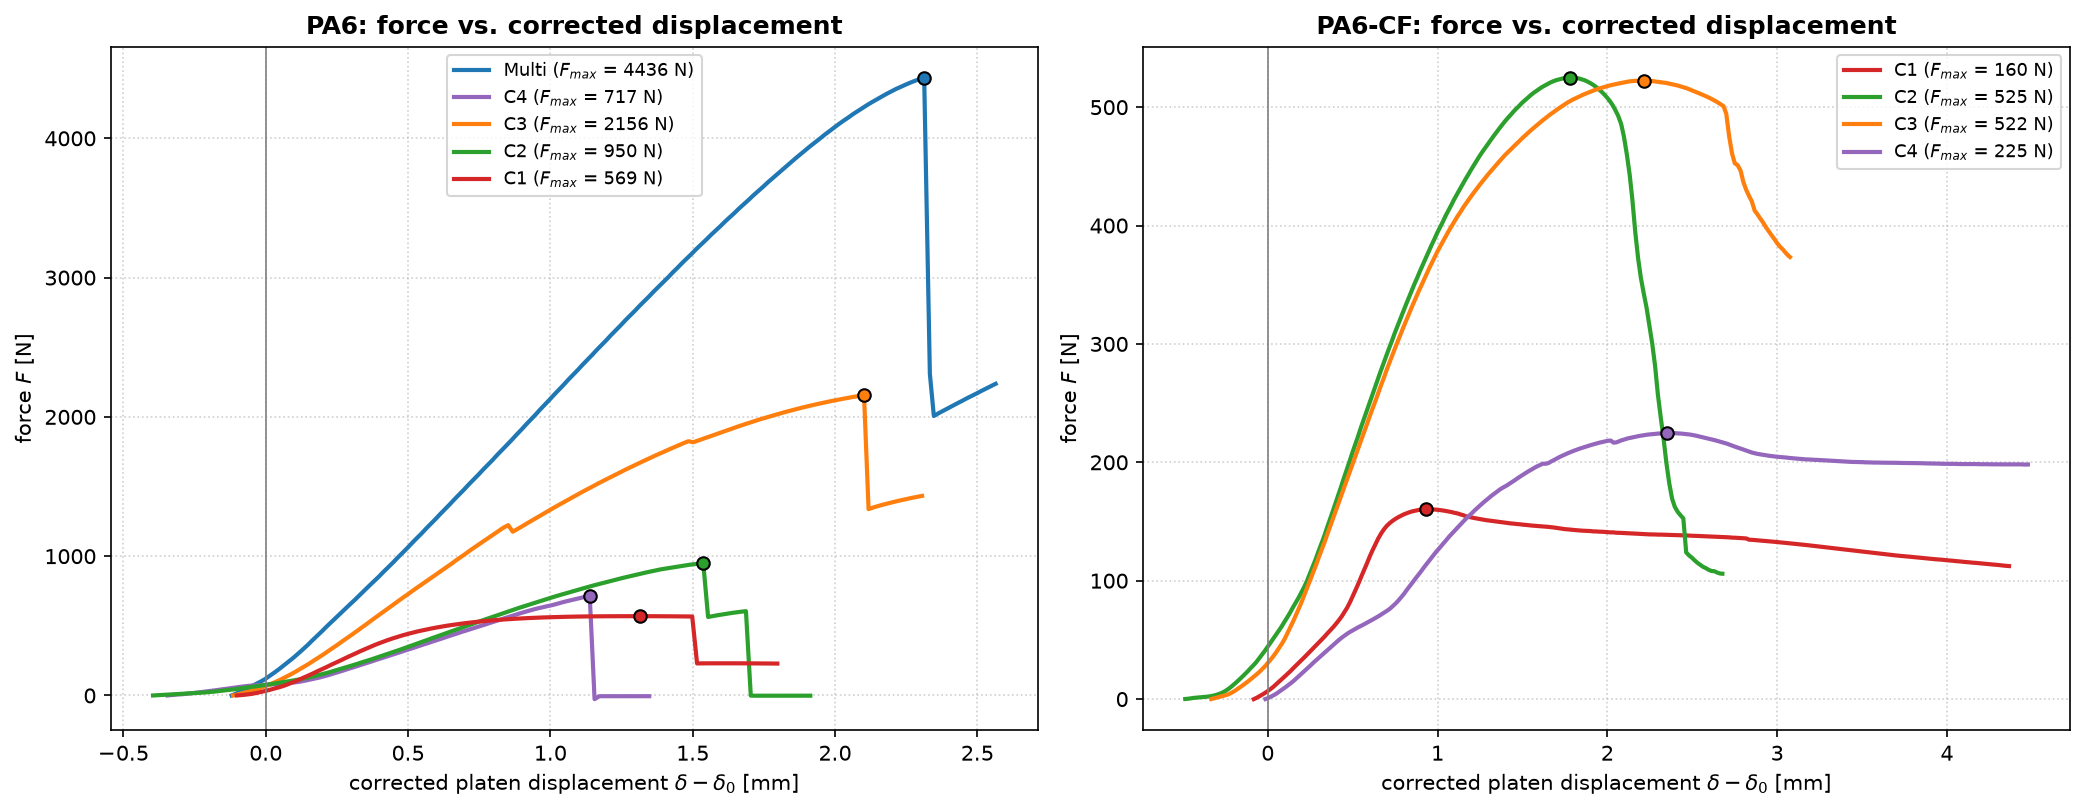

In [9]:
# F_EXP_01: curves after shifting the displacement origin (Figure 5.13.1)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)
for (mat, d), r in curves.items():
    ax = axs[0] if mat == "PA6" else axs[1]
    ax.plot(r["xc"], r["y"], color=COLORS[d], lw=2, label=f"{d} ($F_{{max}}$ = {r['F_max']:.0f} N)")
    ax.plot(r["x_peak"], r["F_max"], "o", color=COLORS[d], mec="k", zorder=5)
for ax, mat in zip(axs, ["PA6", "PA6-CF"]):
    ax.set_title(f"{mat}: force vs. corrected displacement", fontweight="bold")
    ax.set_xlabel(r"corrected platen displacement $\delta - \delta_0$ [mm]"); ax.set_ylabel("force $F$ [N]")
    ax.axvline(0, color="0.5", lw=0.8); ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(OUT / "F_EXP_01_curves_corrected.png", dpi=200)
plt.show()

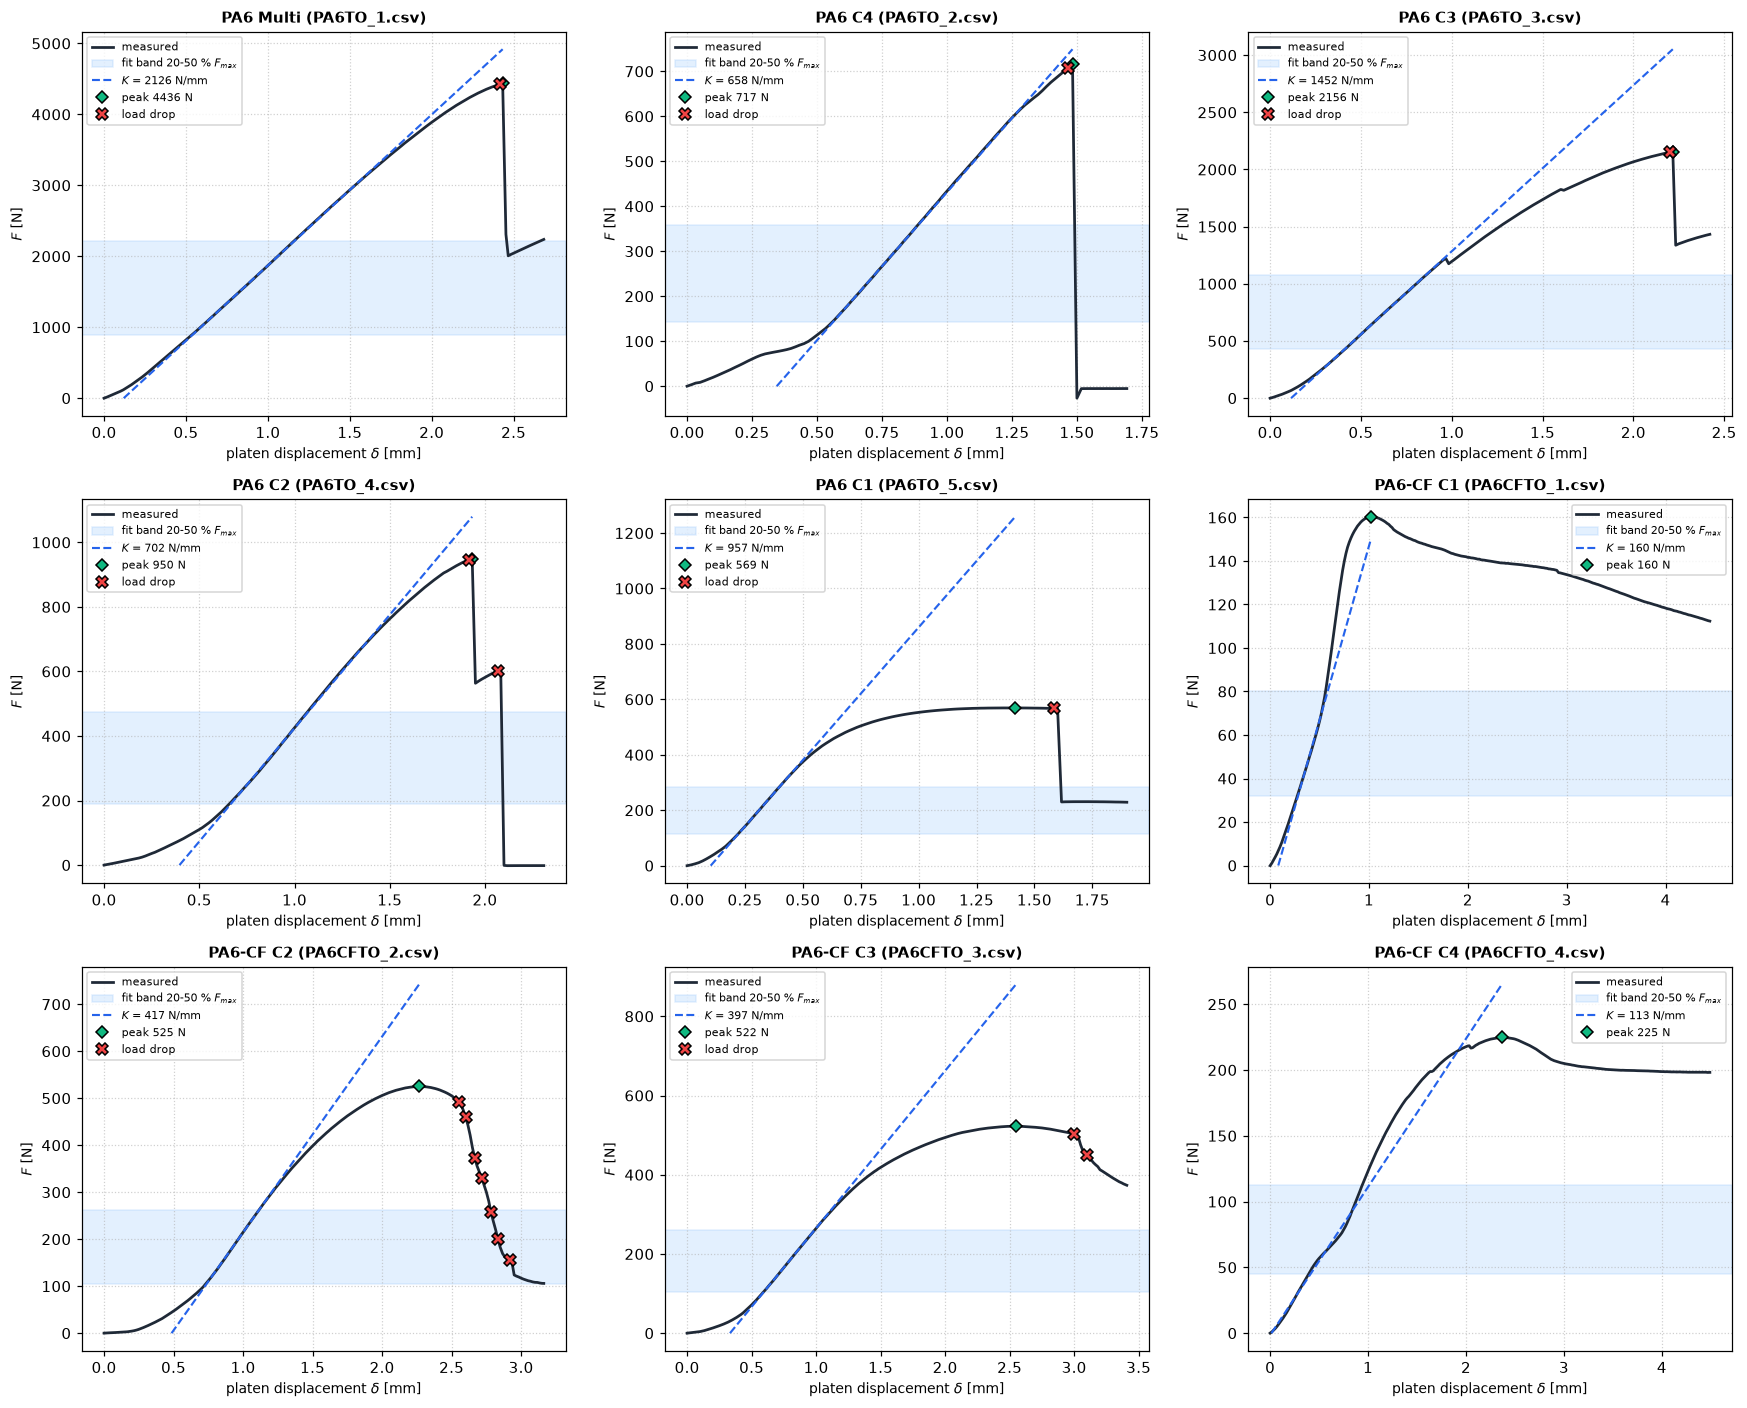

In [10]:
# F_EXP_02: individual curves with their fits, peak and load drops
ncol = 3
nrow = int(np.ceil(len(TESTS) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(16, 4.3 * nrow), dpi=110)
for ax, (mat, fname, d) in zip(axs.ravel(), TESTS):
    r = curves[(mat, d)]
    x, y = r["x"], r["y"]
    ax.plot(x, y, color="#1f2937", lw=1.8, label="measured")
    ax.axhspan(BAND_MAIN[0] * r["F_max"], BAND_MAIN[1] * r["F_max"], color="#93c5fd", alpha=0.25, label="fit band 20-50 % $F_{max}$")
    x_line = np.linspace(r["x0"], x[r["i_peak"]], 50)
    ax.plot(x_line, r["k"] * x_line + r["k_b"], "--", color="#2563eb", lw=1.4, label=f"$K$ = {r['k']:.0f} N/mm")
    ax.plot(x[r["i_peak"]], r["F_max"], "D", color="#10b981", mec="k", label=f"peak {r['F_max']:.0f} N")
    for j, ev in enumerate(r["drops"]):
        ax.plot(ev["x"], ev["F_before"], "X", color="#ef4444", mec="k", ms=8, label="load drop" if j == 0 else None)
    ax.set_title(f"{mat} {d} ({fname})", fontsize=10, fontweight="bold")
    ax.set_xlabel(r"platen displacement $\delta$ [mm]", fontsize=9); ax.set_ylabel("$F$ [N]", fontsize=9); ax.grid(ls=":", alpha=0.6); ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "F_EXP_02_individual_fits.png", dpi=200)
plt.show()

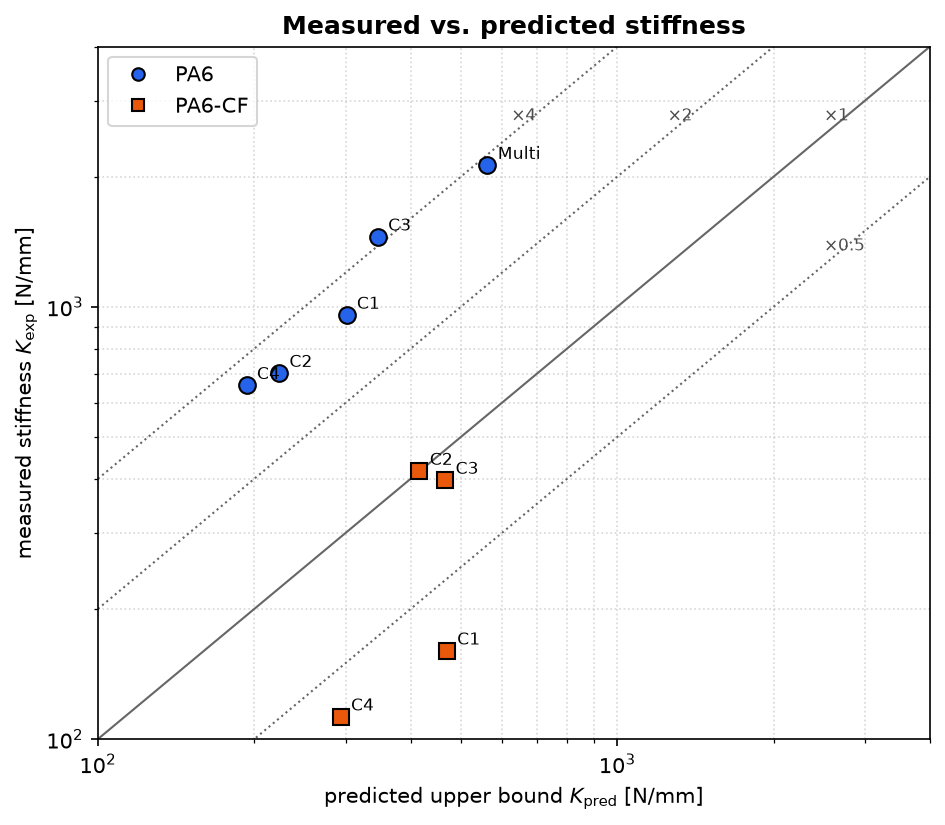

In [11]:
# F_EXP_03: measured stiffness against the prediction (Figure 5.13.2)
fig, ax = plt.subplots(figsize=(6.4, 5.6), dpi=150)
lim = [100, 4000]
for f, ls in [(1, "-"), (2, ":"), (4, ":"), (0.5, ":")]:
    ax.plot(lim, [f * v for v in lim], ls, color="0.4", lw=1)
    xt = min(lim[1] / 1.6, lim[1] / (1.6 * f))
    ax.text(xt, f * xt * 1.08, f"×{f:g}", fontsize=8, color="0.3")
for r in S.itertuples():
    ax.loglog(r.K_pred_N_mm, r.K_exp_N_mm, "o" if r.material == "PA6" else "s", color=MAT_COLORS[r.material], mec="k", ms=8)
    ax.annotate(r.design, (r.K_pred_N_mm, r.K_exp_N_mm), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.plot([], [], "o", color=MAT_COLORS["PA6"], mec="k", label="PA6")
ax.plot([], [], "s", color=MAT_COLORS["PA6-CF"], mec="k", label="PA6-CF")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel(r"predicted upper bound $K_{\mathrm{pred}}$ [N/mm]"); ax.set_ylabel(r"measured stiffness $K_{\mathrm{exp}}$ [N/mm]")
ax.grid(which="both", ls=":", alpha=0.5); ax.legend(); ax.set_title("Measured vs. predicted stiffness", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "F_EXP_03_stiffness_vs_prediction.png", dpi=200)
plt.show()

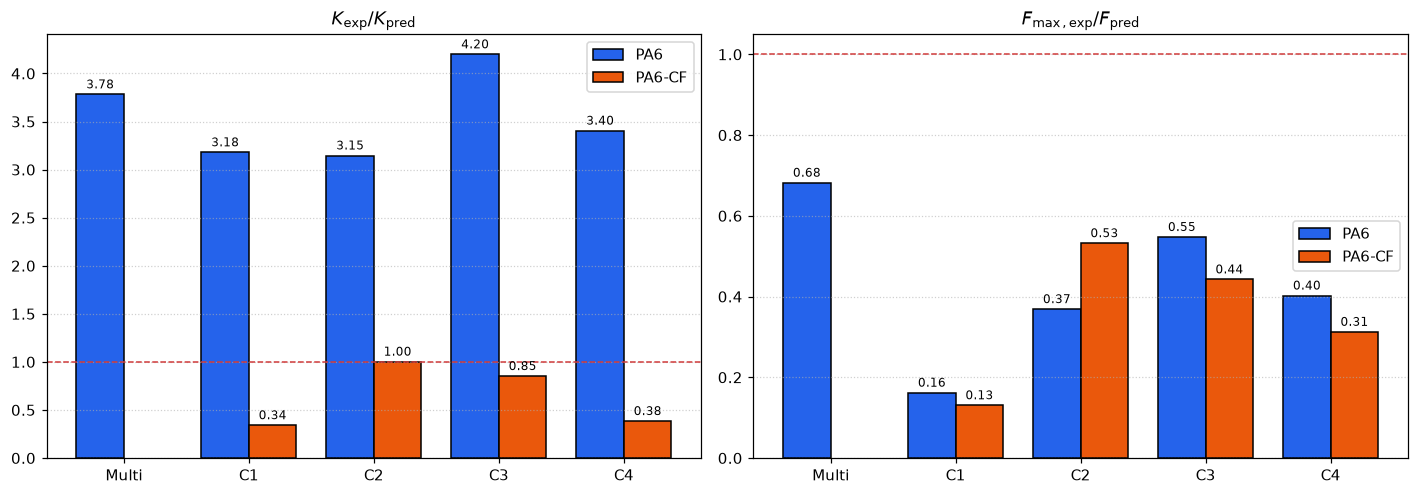

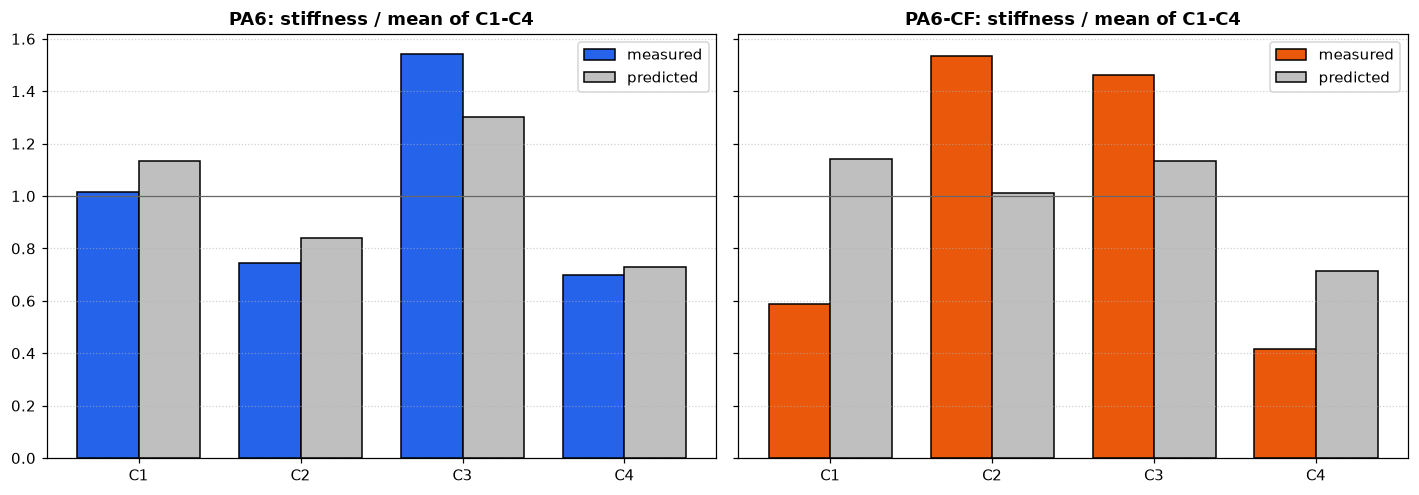

In [12]:
# F_EXP_04: ratios to the predictions, and F_EXP_05: pattern between designs (each material normalized by the mean of C1-C4)
xpos, w = np.arange(len(DESIGN_ORDER)), 0.38
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), dpi=110)
for ax, col, title in [(axs[0], "K_ratio", r"$K_{\mathrm{exp}}/K_{\mathrm{pred}}$"), (axs[1], "F_ratio", r"$F_{\max,\mathrm{exp}}/F_{\mathrm{pred}}$")]:
    for i, mat in enumerate(["PA6", "PA6-CF"]):
        vals = [S[(S.material == mat) & (S.design == d)][col].values for d in DESIGN_ORDER]
        vals = [v[0] if len(v) else np.nan for v in vals]
        bars = ax.bar(xpos + (i - 0.5) * w, vals, w, color=MAT_COLORS[mat], edgecolor="k", label=mat)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.axhline(1, color="#d03b3b", ls="--", lw=1); ax.set_xticks(xpos, DESIGN_ORDER); ax.set_title(title, fontweight="bold"); ax.grid(axis="y", ls=":", alpha=0.6); ax.legend()
fig.tight_layout()
fig.savefig(OUT / "F_EXP_04_ratios_to_prediction.png", dpi=200)
plt.show()

cases = ["C1", "C2", "C3", "C4"]
xp = np.arange(len(cases))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), dpi=110, sharey=True)
for ax, mat in zip(axs, ["PA6", "PA6-CF"]):
    s = S[(S.material == mat) & (S.design.isin(cases))].set_index("design").loc[cases]
    ax.bar(xp - w / 2, s.K_exp_N_mm / s.K_exp_N_mm.mean(), w, color=MAT_COLORS[mat], edgecolor="k", label="measured")
    ax.bar(xp + w / 2, s.K_pred_N_mm / s.K_pred_N_mm.mean(), w, color="0.75", edgecolor="k", label="predicted")
    ax.set_xticks(xp, cases); ax.axhline(1, color="0.4", lw=0.8); ax.set_title(f"{mat}: stiffness / mean of C1-C4", fontweight="bold"); ax.grid(axis="y", ls=":", alpha=0.6); ax.legend()
fig.tight_layout()
fig.savefig(OUT / "F_EXP_05_pattern_between_designs.png", dpi=200)
plt.show()

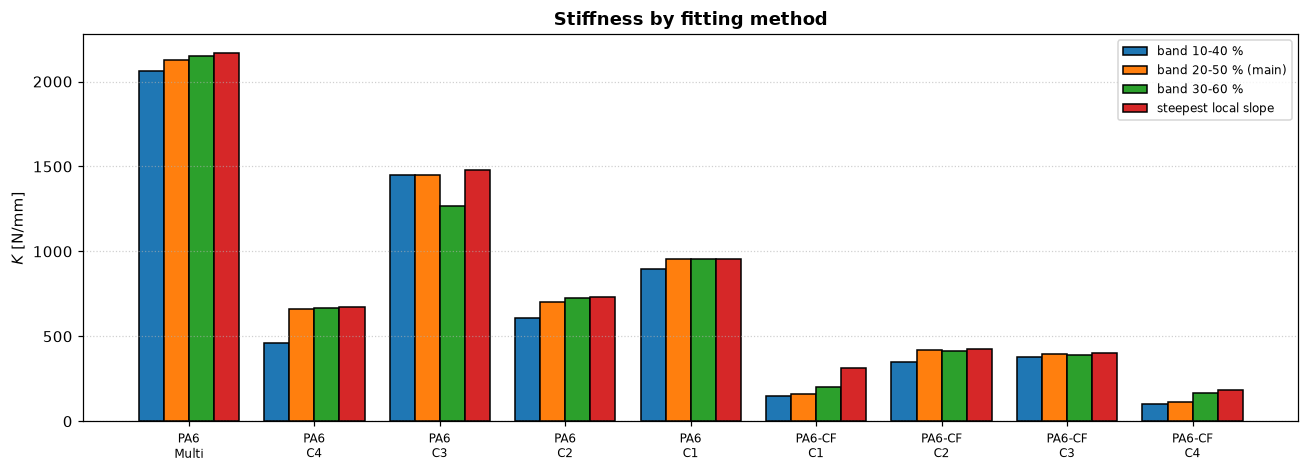

In [13]:
# F_EXP_06: sensitivity of the stiffness to the fitting method
fig, ax = plt.subplots(figsize=(12, 4.4), dpi=110)
xp, ww = np.arange(len(S)), 0.2
for j, (col, lab) in enumerate([("K_10_40", "band 10-40 %"), ("K_exp_N_mm", "band 20-50 % (main)"), ("K_30_60", "band 30-60 %"), ("K_steepest", "steepest local slope")]):
    ax.bar(xp + (j - 1.5) * ww, S[col], ww, label=lab, edgecolor="k")
ax.set_xticks(xp, [f"{r.material}\n{r.design}" for r in S.itertuples()], fontsize=8)
ax.set_ylabel("$K$ [N/mm]"); ax.set_title("Stiffness by fitting method", fontweight="bold"); ax.grid(axis="y", ls=":", alpha=0.6); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "F_EXP_06_stiffness_methods.png", dpi=200)
plt.show()

## 8. Check against the thesis

The values of Table 5.13.1 and the statistics of Section 5.13.1 are compared with this run, at the precision with which the thesis prints them.

In [14]:
T5131 = {("PA6", "Multi"): (2.126, 3.78, 4.436, 0.68, 2.31, 2.86), ("PA6", "C1"): (0.957, 3.18, 0.569, 0.16, 1.32, 1.62), ("PA6", "C2"): (0.702, 3.15, 0.950, 0.37, 1.54, 1.90),
         ("PA6", "C3"): (1.452, 4.20, 2.156, 0.55, 2.10, 2.60), ("PA6", "C4"): (0.658, 3.40, 0.717, 0.40, 1.14, 1.41), ("PA6-CF", "C1"): (0.160, 0.34, 0.160, 0.13, 0.94, 1.15),
         ("PA6-CF", "C2"): (0.417, 1.00, 0.525, 0.53, 1.78, 2.20), ("PA6-CF", "C3"): (0.397, 0.85, 0.522, 0.44, 2.22, 2.74), ("PA6-CF", "C4"): (0.113, 0.38, 0.225, 0.31, 2.35, 2.91)}
checks = []
def check(name, computed, printed, decimals):
    # Within half a unit of the last printed digit, plus a margin for values rounded in two steps (2.5949 -> 2.595 -> 2.60).
    checks.append(dict(item=name, computed=float(computed), thesis=float(printed), agrees=abs(float(computed) - float(printed)) <= 0.55 * 10.0 ** (-decimals)))

for r in S.itertuples():
    v = T5131[(r.material, r.design)]
    for lab, val, printed, dec in [("K_exp [kN/mm]", r.K_exp_N_mm / 1e3, v[0], 3), ("K_exp/K_pred", r.K_ratio, v[1], 2), ("F_max [kN]", r.F_max_N / 1e3, v[2], 3), ("F_max/F_pred", r.F_ratio, v[3], 2),
                                   ("delta_max [mm]", r.delta_max_mm, v[4], 2), ("delta_max/H [%]", r.delta_max_over_H_pct, v[5], 2)]:
        check(f"{r.material} {r.design} {lab}", val, printed, dec)
pa6, cf = ST[ST.material == "PA6"].iloc[0], ST[ST.material == "PA6-CF"].iloc[0]
check("PA6 mean ratio", pa6.ratio_mean, 3.54, 2); check("PA6 ratio CV [%]", pa6.ratio_cv_pct, 12.6, 1); check("PA6 Spearman", pa6.spearman_rho, 1.0, 1)
check("PA6-CF ratio CV [%]", cf.ratio_cv_pct, 51.5, 1); check("PA6-CF Spearman", cf.spearman_rho, 0.2, 1)
report_check = pd.DataFrame(checks)
report_check.to_csv(OUT / "report_check.csv", index=False)
print(f"{int(report_check.agrees.sum())} of {len(report_check)} values agree with the thesis at its printed precision")
report_check[~report_check.agrees]

59 of 59 values agree with the thesis at its printed precision


,item,computed,thesis,agrees
